![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)

# Laboratory 3. Circuits and Compact Models

This notebook builds compact optical models into circuits, then explores their wavelength-dependent **power transmission**.

## How to use this notebook

Follow the path from **component → circuit → response**. Run the notebook from top to bottom. In each simulation, the marked parameters are the ones to vary for the laboratory tasks.

1. Build a waveguide and an ideal coupler model.
2. Connect them into a Mach–Zehnder interferometer (MZI).
3. Reuse the same components in single-bus and two-bus ring resonators.
4. Relate each circuit’s response to path length, coupling, and propagation loss.

### Conventions used throughout

| Quantity | Meaning | Units in this notebook |
|---|---|---|
| `wl`, `length`, `delta_l` | Wavelengths and waveguide lengths | µm |
| `loss` | Propagation power loss per length | dB/cm |
| `H` or `S[i, j]` | Complex field transmission between ports | complex amplitude |
| `abs(H)**2` | Relative power transmission | linear |
| `10 log10(abs(H)**2)` | Relative power transmission | dB |

The component models pass complex amplitudes to SAX. The plotted quantity is usually power, so the dB conversion uses `10*log10(power)`.

## 0. Setup

In [1]:
import logging
import sys

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import sax
from matplotlib.pyplot import cm
from rich.logging import RichHandler
from scipy.constants import c as c0

logger = logging.getLogger()
logger.removeHandler(sys.stderr)
logging.basicConfig(level="WARNING", datefmt="[%X]", handlers=[RichHandler()])

## 1. Component models

A compact model describes how a component transforms the complex field amplitudes at its ports. The diagram separates the model output, `H`, from the relative power transmission, `|H|²`.

![Field amplitude and power transmission](lab3_assets/field_power.svg)

### 1.1 Waveguide compact model

We start from the waveguide's effective index second degree polynomial:

$$
n_\mathrm{eff}(\lambda)
= n_{1} + n_{2}\,(\lambda-\lambda_{0}) + n_{3}\,(\lambda-\lambda_{0})^{2}
$$

Or from the parameters derived from the polynomial coefficients: 
 
$$
n_\mathrm{eff}(\lambda_0) = n_1~ ;~ n_g(\lambda_0) = n_1 - n_2\,\lambda_0~;~ D = -\frac{2\,\lambda_0\,n_3}{c}\;\;[\mathrm{s}^2/\mathrm{m}]
$$

The transmmission through the waveguide should be modeled as: 

$$
H(\lambda)
= e^{-j\,\beta(\lambda)\,z}
= e^{-j\,\mathrm{Re}\{\beta(\lambda)\}\,z}\,
  e^{\mathrm{Im}\{\beta(\lambda)\}\,z}.
$$
With  
$$
\beta(\lambda)
= \frac{2\pi}{\lambda}\,\mathrm{Re}\{n_\mathrm{eff}(\lambda)\}.
$$

We are going to use [SAX](https://pypi.org/project/sax/), a scatter parameter circuit simulator, to implement simulations in the frequency (wavelength) domain. The following cell demonstrates how to define the most basic component transfer function: 

In [2]:
# The model should be a Python function that takes as input the relevant parameters
# (e.g., wavelength, effective index, length, loss) and returns a SAX SDict representing
# the waveguide's S-parameters.
# Parameters:
# wl: Wavelength to simulate (um)
# wl0: Reference wavelength - where you calculated the group index and dispersion (um))
# neff: Effective index at the reference wavelength (au)
# ng: Group index (au)
# length: Length of the waveguide in micrometers (um)
# loss: Propagation loss in dB/cm (Experimental value)
# D: Dispersion parameter (s^2/m)
def waveguide(wl=1.55, wl0=1.55, neff=1.6072, ng=2.0, length=10.0, loss=0.0, D=0) -> sax.SDict:
    dwl = wl - wl0
    n1 = neff
    n2 = (n1-ng)/wl0
    n3 = -D*c0/(2*wl0)
    neff = n1 + n2*dwl + n3*dwl**2
    phase = 2 * jnp.pi * neff * length / wl
    # Convert waveguide length from um to cm, then convert total power loss to amplitude
    total_loss_dB = loss * length / 1e4
    transmission = 10 ** (-total_loss_dB / 20) * jnp.exp(1j * phase)
    wg_dict = sax.reciprocal(
        {
            ("in0", "out0"): transmission,
        }
    )
    return wg_dict

### 1.2 Ideal coupler compact model

Here `K` is the fraction of input power sent to the cross-coupled output. The model is an ideal, lossless, reciprocal 2×2 coupler with a fixed cross-coupling phase of −π/2. The Laboratory 2 results can later be used to replace the ideal parameters.

$$
\begin{pmatrix}
E_{o1}\\
E_{o2}
\end{pmatrix}
=
\begin{pmatrix}
\sqrt{1-K} & -\mathrm{j}\sqrt{K}\\
-\mathrm{j}\sqrt{K} & \sqrt{1-K}
\end{pmatrix}
\begin{pmatrix}
E_{i1}\\
E_{i2}
\end{pmatrix}
$$

![Coupler field-amplitude relation and power split](lab3_assets/coupler.svg)

In [3]:
# Coupler Model
# We define again the Python function for the coupler compact model.
# Parameters:
# coupling: Coupling coefficient (between 0 and 1)
# You MUST update the model with the parameters you found in your Laboratory 2: 
def coupler(coupling=0.5) -> sax.SDict:
    kappa = coupling**0.5
    tau = (1 - coupling) ** 0.5
    # The coupler is a reciprocal device, so we use sax.reciprocal to create the SDict
    # (reciprocal device means it behaves the same way in both directions)
    coupler_dict = sax.reciprocal(
        {
            ("in0", "out0"): tau,
            ("in0", "out1"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out0"): kappa * np.exp(-1j * np.pi / 2.0),
            ("in1", "out1"): tau,
        }
    )
    return coupler_dict


## 2. Mach–Zehnder interferometer

Use the original MZI drawing to orient yourself, then compare the named components and ports with the netlist.

![MZI circuit](mzi.png)

### 2.1 Circuit definition

In [4]:
# MZI Circuit
# We will define instances, connections and ports for the MZI circuit using the SAX library.
# We will use the coupler and waveguide models defined above.
mzi, info = sax.circuit(
    netlist={
        # Define instances of couplers and waveguides
        "instances": {
            "coup_E": "coupler",
            "wvg_N": "waveguide",
            "wvg_S": "waveguide",
            "coup_W": "coupler",
        },
        # Define connections between the instances
        "connections": {
            "coup_E,out0": "wvg_S,in0",
            "wvg_S,out0": "coup_W,in0",
            "coup_E,out1": "wvg_N,in0",
            "wvg_N,out0": "coup_W,in1",
        },
        # Define the external ports of the MZI circuit
        "ports": {
            "in0": "coup_E,in0",
            "in1": "coup_E,in1",
            "out0": "coup_W,out0",
            "out1": "coup_W,out1",
        },
    },
    # Important! Provide here the models for the components used in the circuit
    # Here we use the coupler and waveguide functions defined above
    models={
        "coupler": coupler,
        "waveguide": waveguide,
    },
)


### 2.2 Simulate the MZI

The helper below keeps the four response plots consistent. It plots linear power and power in dB; the conversion is `10*log10(|H|²)`. The circuit simulation itself remains visible in each section.

In [5]:
def plot_power_transmission(wl_um, traces, linear_ylim=None, db_ylim=None):
    """Plot complex port responses as linear power and power in dB.

    Each trace is (label, complex_field_transmission, linestyle).
    """
    fig, axes = plt.subplots(2, 1, figsize=(9, 7))
    colors = cm.rainbow(np.linspace(0, 1, len(traces)))

    for color, (label, H, linestyle) in zip(colors, traces):
        power = np.abs(H) ** 2
        power_dB = 10.0 * np.log10(power)
        axes[0].plot(wl_um * 1e3, power, linestyle=linestyle, color=color, label=label)
        axes[1].plot(wl_um * 1e3, power_dB, linestyle=linestyle, color=color, label=label)

    axes[0].set_ylabel("Power transmission |H|² [linear]")
    axes[1].set_ylabel("Power transmission [dB]")
    for axis in axes:
        axis.grid(True)
        axis.set_xlabel("Wavelength [nm]")
        axis.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
    if linear_ylim is not None:
        axes[0].set_ylim(linear_ylim)
    if db_ylim is not None:
        axes[1].set_ylim(db_ylim)
    fig.tight_layout()
    return fig, axes

(<Figure size 900x700 with 2 Axes>,
 array([<Axes: xlabel='Wavelength [nm]', ylabel='Power transmission |H|² [linear]'>,
        <Axes: xlabel='Wavelength [nm]', ylabel='Power transmission [dB]'>],
       dtype=object))

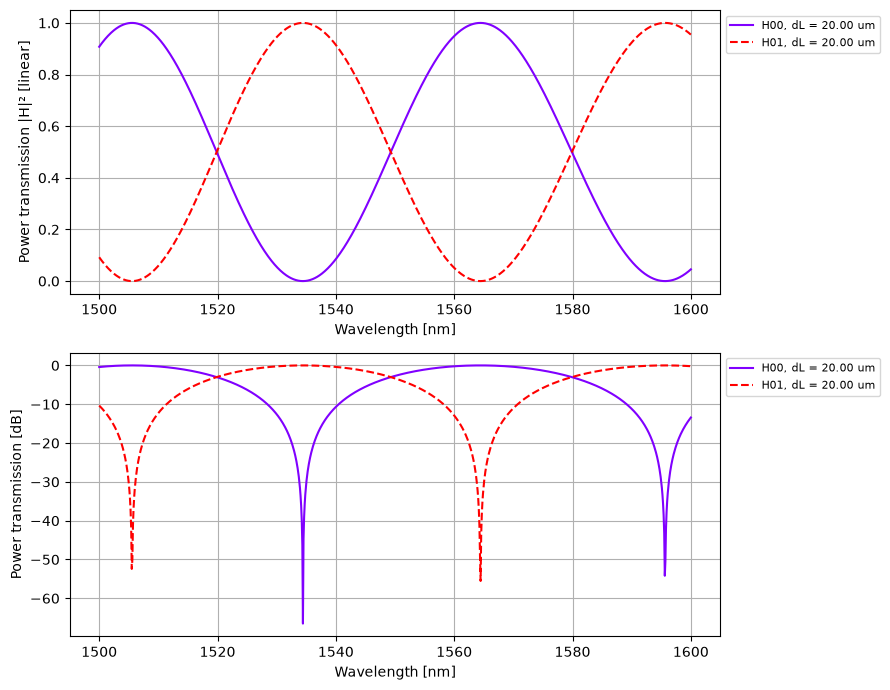

In [6]:
# Wavelength range and number of samples
wl = jnp.linspace(1.50, 1.60, 1000)

# Parameters to vary: arm length difference (um) and common base length (um)
delta_l_v = np.array([20,])
l_base = 10.0

traces = []
for delta_l in delta_l_v:
    mzi_result = mzi(
        wl=wl,
        wvg_S={"length": l_base},
        wvg_N={"length": l_base + delta_l},
    )
    traces.append((f"H00, dL = {delta_l:.2f} um", mzi_result["in0", "out0"], "-"))
    traces.append((f"H01, dL = {delta_l:.2f} um", mzi_result["in0", "out1"], "--"))

plot_power_transmission(wl, traces)

The resulting interference pattern allows us to determine the **free spectral range** (FSR). By locating two adjacent notches in the transfer function, the difference between their wavelengths gives the FSR, which satisfies:

$$
\Delta\lambda_{\mathrm{FSR}}
= \frac{\lambda^{2}}{n_g(\lambda)\,\Delta L}
$$

You can use this code section with certain variations for LO1a,1b,2 and 3.

## 3. Ring resonators

The same waveguide and coupler models can be connected into two ring configurations. Each circuit figure appears immediately before its netlist.

### 3.1 Single-bus ring response

The ring waveguide returns the coupled field to the coupler on each round trip. At resonance, these circulating fields interfere with the bus field and change the through-port transmission. Its netlist is shown directly below the overview figure.

![Single-bus ring circuit](ring_s.png)

In [7]:
ring_ap, info = sax.circuit(
    netlist={
        "instances": {
            "coup": "coupler",
            "wvg_ring": "waveguide",
        },
        "connections": {
            "coup,out1": "wvg_ring,in0",
            "wvg_ring,out0": "coup,in1",
        },
        "ports": {
            "in0": "coup,in0",
            "out0": "coup,out0"
        },
    },
    models={
        "coupler": coupler,
        "waveguide": waveguide,
    },
)

#### Simulate the through-port response

(<Figure size 900x700 with 2 Axes>,
 array([<Axes: xlabel='Wavelength [nm]', ylabel='Power transmission |H|² [linear]'>,
        <Axes: xlabel='Wavelength [nm]', ylabel='Power transmission [dB]'>],
       dtype=object))

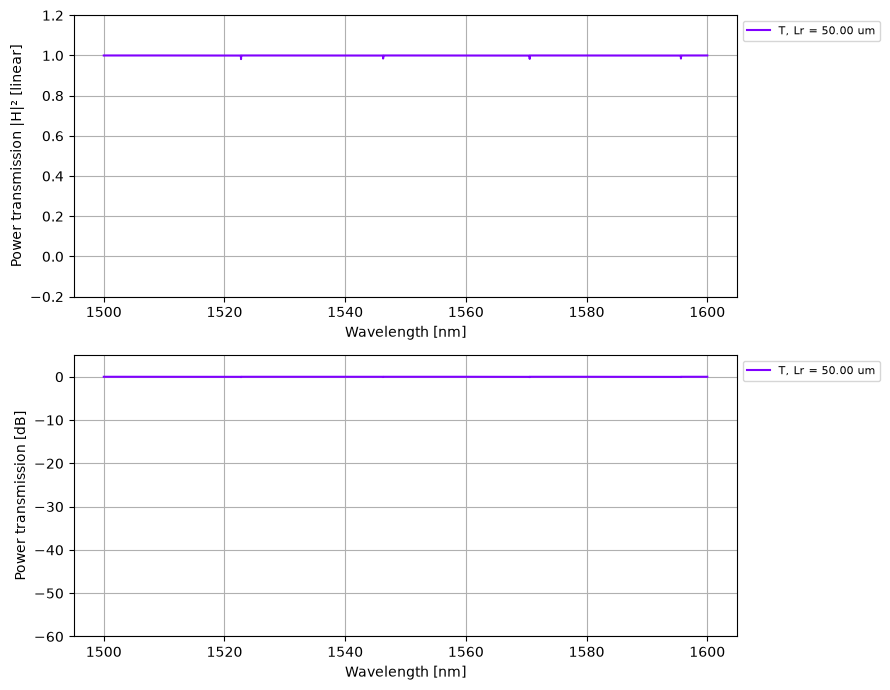

In [ ]:
wl = jnp.linspace(1.50, 1.60, 10000)
ring_lengths_um = np.array([50,])
coupling = 0.005
loss_dBcm = 200

traces = []
for ring_length_um in ring_lengths_um:
    ring_result = ring_ap(
        wl=wl,
        wvg_ring={"length": ring_length_um, "loss": loss_dBcm},
        coup={"coupling": coupling},
    )
    traces.append((f"T, Lr = {ring_length_um:.2f} um", ring_result["in0", "out0"], "-"))

plot_power_transmission(wl, traces, linear_ylim=(-0.2, 1.2), db_ylim=(-60, 5))

The ring response is periodic in wavelength. The **free spectral range** (FSR), using the ring perimeter $L_r$, is approximately:

$$
\Delta\lambda_{\mathrm{FSR}}
= \frac{\lambda^{2}}{n_g(\lambda)\,L_r}
$$

Where $L_r$ is the ring perimeter. Note that in our circuit model, we neglect the length of the coupler, so the perimeter is defined by the length of the waveguide sections.

### 3.2 Two-bus ring

The second coupler creates a drop port. The ring perimeter is split into the two sections `wvg_ring_E` and `wvg_ring_W`; their lengths add to `Lr`.

![Double-bus ring circuit](ring_d.png)

In [9]:
ring_2bus, info = sax.circuit(
    netlist={
        "instances": {
            "wvg_S_in": "waveguide",
            "wvg_S_out": "waveguide",
            "coup_S": "coupler",
            "wvg_ring_E": "waveguide",
            "wvg_ring_W": "waveguide",
            "coup_N": "coupler",
            "wvg_N_in": "waveguide",
            "wvg_N_out": "waveguide",
        },
        "connections": {
            "wvg_S_in,out0": "coup_S,in0",
            "coup_S,out0": "wvg_S_out,in0",
            "coup_S,out1": "wvg_ring_E,in0",
            "wvg_ring_E,out0": "coup_N,in1",
            "coup_N,out1": "wvg_ring_W,in0",
            "wvg_ring_W,out0": "coup_S,in1",
            "wvg_N_in,out0": "coup_N,in0",
            "coup_N,out0": "wvg_N_out,in0",
        },
        "ports": {
            "in0": "wvg_S_in,in0",
            "out0": "wvg_S_out,out0",
            "in1": "wvg_N_in,in0",
            "out1": "wvg_N_out,out0",
        },
    },
    models= {
        "coupler": coupler,
        "waveguide": waveguide,
    },
)

#### Simulate through and drop responses

(<Figure size 900x700 with 2 Axes>,
 array([<Axes: xlabel='Wavelength [nm]', ylabel='Power transmission |H|² [linear]'>,
        <Axes: xlabel='Wavelength [nm]', ylabel='Power transmission [dB]'>],
       dtype=object))

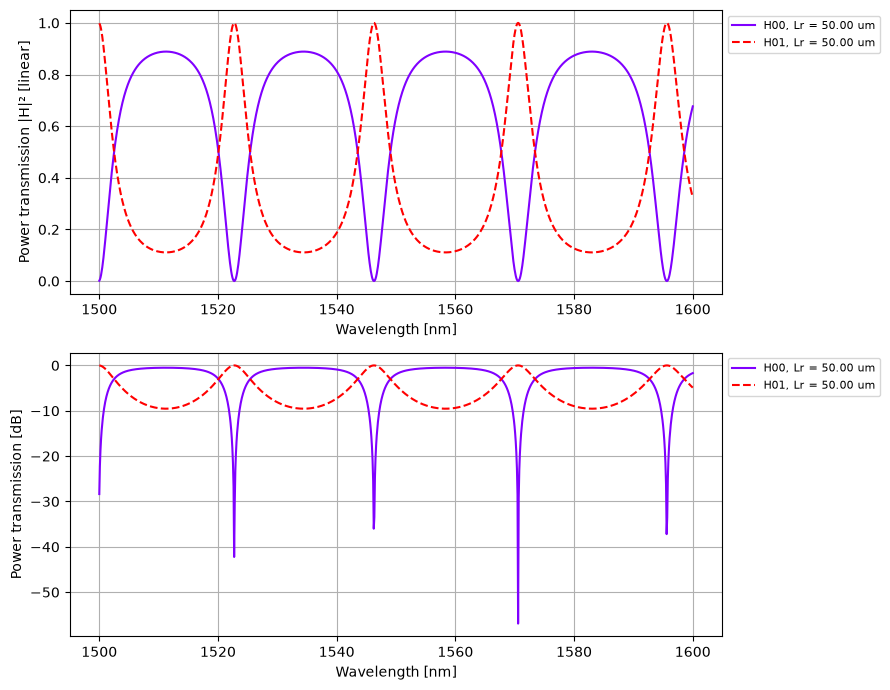

In [10]:
wl = jnp.linspace(1.50, 1.60, 1000)
ring_perimeters_um = np.array([50,])

traces = []
for ring_perimeter_um in ring_perimeters_um:
    ring_result = ring_2bus(
        wl=wl,
        wvg_ring_E={"length": 0.5 * ring_perimeter_um},
        wvg_ring_W={"length": 0.5 * ring_perimeter_um},
    )
    traces.append((f"H00, Lr = {ring_perimeter_um:.2f} um", ring_result["in0", "out0"], "-"))
    traces.append((f"H01, Lr = {ring_perimeter_um:.2f} um", ring_result["in0", "out1"], "--"))

plot_power_transmission(wl, traces)

### 3.3 Explore propagation loss

The next example zooms in on one resonance and sweeps propagation loss. Values are entered directly in dB/cm; the waveguide model converts them internally using the section length in µm.

(<Figure size 900x700 with 2 Axes>,
 array([<Axes: xlabel='Wavelength [nm]', ylabel='Power transmission |H|² [linear]'>,
        <Axes: xlabel='Wavelength [nm]', ylabel='Power transmission [dB]'>],
       dtype=object))

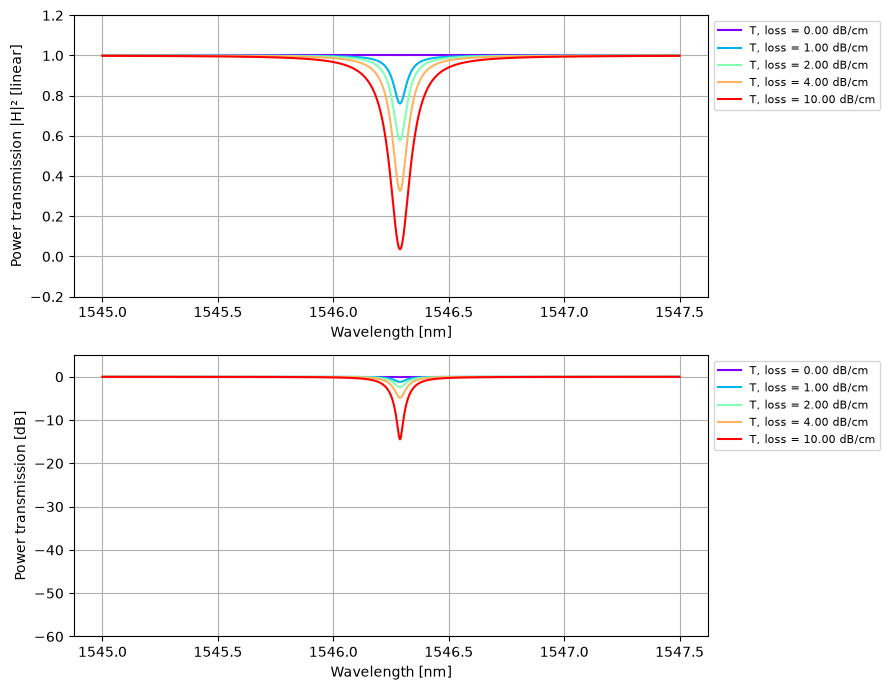

In [11]:
wl = jnp.linspace(1.545, 1.5475, 1000)
loss_dBcm_values = np.array([0, 1, 2, 4, 10])
ring_perimeter_um = 75.0
coupling = 0.025

traces = []
for loss_dBcm in loss_dBcm_values:
    ring_result = ring_ap(
        wl=wl,
        wvg_ring={"length": ring_perimeter_um, "loss": loss_dBcm},
        coup={"coupling": coupling},
    )
    traces.append((f"T, loss = {loss_dBcm:.2f} dB/cm", ring_result["in0", "out0"], "-"))

plot_power_transmission(wl, traces, linear_ylim=(-0.2, 1.2), db_ylim=(-60, 5))

## 4. Laboratory tasks and checkpoints

Use the examples above to obtain the results for LO1–LO6. For each variation:

- State which parameter you changed and its units.
- Identify the ports represented by the plotted responses.
- Compare the observed resonance or fringe spacing with the relevant FSR relation.
- Explain how coupling and propagation loss change the response.